# Projeto Prático 2.1 - Aprendizado Supervisionado no Neurônio Perceptron

**Redes Neurais Artificiais - 2026/2** - Escola Superior de Tecnologia (UEA)
- Profa. Elloá B. Guedes (ebgcosta@uea.edu.br)
- http://github.com/elloa

### Equipe

- Julia Cohen (github.com/jubcohen) - 2415080008
- Pedro Portela (github.com/portelapedro) - 2415080038

  Identificador da dupla: (8 + 8) % 4 = **0**

Este notebook implementa o algoritmo de treinamento do neurônio Perceptron de Rosenblatt. Ele está organizado em duas camadas:

1. **Funções reutilizáveis** (Seção 1): leitura dos dados, operações do neurônio, laço de treinamento, visualização e relatório.
2. **Partes da atividade** (Seção 2 em diante): cada parte apenas define seus parâmetros e chama as funções da Seção 1.

## 1. Funções reutilizáveis

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import random
from dataclasses import dataclass
from prettytable import PrettyTable  
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay,
                             accuracy_score, precision_score,
                             recall_score, f1_score)
import pandas as pd

# esquema de cores exigido pela atividade: classe 0 em vermelho, classe 1 em azul
CORES_CLASSES = {0: 'red', 1: 'blue'}
# identificador da dupla: (8 + 8) % 4 = 0
identificador = 0

### 1.1 Leitura dos dados

Cada arquivo contém um `numpy.ndarray` salvo em binário com dimensões `(m, 1, 3)`, em que cada exemplo é `(x1, x2, yd)`. A função devolve os atributos `X` com formato `(m, 2)` e os rótulos `yd` com formato `(m,)`.

O viés **não** é adicionado aqui: ele é responsabilidade do neurônio (função `adicionar_vies`). Assim, `X` continua representando apenas os pontos do $\mathbb{R}^2$ e pode ser usado diretamente nos gráficos e na divisão treino/teste.

`normalizar_atributos` leva **cada atributo separadamente** (cada coluna de `X`) para o intervalo $[-1, 1]$ por min-max:

$$x' = 2\,\frac{x - \min}{\max - \min} - 1$$

Na Parte III, os limites de máximo e mínimo são calculados apenas com o conjunto de treino e reaplicados no teste, para que nenhuma informação do teste participe do treinamento (evitar data leakage). Por ser uma transformação linear de cada eixo, a normalização não muda a natureza do problema: o que era linearmente separável continua sendo, e o que não era continua não sendo.

In [2]:
def carregar_dados(caminho):
    """Lê um arquivo binário (m, 1, 3) e devolve X (m, 2) e yd (m,)."""
    # aceita (m, 1, 3) ou (m, 3): o reshape deixa uma linha por exemplo
    dados = np.load(caminho).reshape(-1, 3)
    X = dados[:, :2]                # atributos x1 e x2
    yd = dados[:, 2].astype(int)    # rótulos 0 ou 1
    print(np.load(caminho).shape)
    print(f"[{caminho}] {X.shape[0]} exemplos carregados "
          f"(classe 0: {np.sum(yd == 0)}, classe 1: {np.sum(yd == 1)}).")
    return X, yd

def normalizar_atributos(X, limites=None):
    """
    Leva cada atributo (coluna) de X para [-1, 1] por min-max.

    limites : (minimos, maximos); se None, são calculados a partir de X
    Devolve X normalizado e os limites usados, para reaplicá-los em outro conjunto.
    """
    # calcula os limites só quando não foram informados (ex.: no conjunto de treino)
    if limites is None:
        limites = (X.min(axis=0), X.max(axis=0))
    minimos, maximos = limites
    # (X - min) / (max - min) leva para [0, 1]; "* 2 - 1" desloca para [-1, 1]
    return 2 * (X - minimos) / (maximos - minimos) - 1, limites

### 1.2 Operações do neurônio

- `adicionar_vies`: acrescenta a entrada fixa $x_0 = -1$, de modo que $w_0$ faz o papel do limiar.
- `inicializar_pesos`: sorteia $w_i \sim U(a, b)$ para o intervalo informado.
- `degrau`: função de ativação degrau com limiar $\vartheta$ (padrão $\vartheta = 0$). Funciona tanto para um único valor quanto para um vetor.
- `prever`: calcula a saída do neurônio para **todos** os exemplos de uma vez, com uma única multiplicação matricial.

In [3]:
def adicionar_vies(X):
    """Acrescenta a coluna x0 = -1 à esquerda de X."""
    # coluna de -1 com uma linha por exemplo, colada antes de x1 e x2
    return np.hstack((-np.ones((X.shape[0], 1)), X))


def inicializar_pesos(intervalo, n_pesos=3, rng=None):
    """Sorteia o vetor de pesos w ~ U(intervalo[0], intervalo[1])."""
    # default_rng aceita uma semente (int), um Generator já criado ou None (sem semente)
    rng = np.random.default_rng(rng)
    return rng.uniform(intervalo[0], intervalo[1], n_pesos)


def degrau(u, theta=0.0):
    """Função de ativação degrau: 1 se u >= theta, senão 0."""
    # np.where funciona tanto para um único potencial quanto para um vetor deles
    return np.where(u >= theta, 1, 0)


def prever(X, w, theta=0.0):
    """Saída do neurônio para todos os exemplos de X (sem a coluna de viés)."""
    # (m, 3) @ (3,) -> (m,): o potencial u de todos os exemplos numa só operação
    return degrau(adicionar_vies(X) @ w, theta)

### 1.3 Treinamento

`treinar_perceptron` concentra a regra de aprendizado do Perceptron, $\mathbf{w} \leftarrow \mathbf{w} + \eta\,e\,\mathbf{x}$, com $e = y_d - y$. O mesmo código atende às três partes da atividade por meio dos parâmetros:

| Parâmetro | Parte I | Parte II | Parte III |
|---|---|---|---|
| `eta`, `intervalo` | 0,1 e (−0,5, +0,5) | as 6 combinações | recomendação da literatura |
| `max_epocas` | `None` (até convergir) | `None` (até convergir) | 100 |
| `embaralhar` | `False` | `False` | `True` |
| `rng` | livre | sorteada a cada execução (e impressa) | semente da equipe |

**Critério de parada.** O treinamento termina quando uma época inteira passa sem erros (convergência) ou quando `max_epocas` é atingido. Se uma época não tem erros, os pesos não mudam e todas as épocas seguintes também não teriam erros, então parar ali é sempre seguro.

**Contagem de épocas.** `epocas` é o número de épocas executadas, **incluindo** a última, sem erros, que comprova a convergência. Cada erro gera exatamente um ajuste, então o total de ajustes é a soma dos erros de todas as épocas.


In [4]:
@dataclass
class ResultadoTreinamento:
    """Tudo o que uma execução de treinamento produz."""
    w_inicial: np.ndarray    # pesos sorteados antes do treino
    w_final: np.ndarray      # pesos ao fim do treino
    total_ajustes: int       # soma dos erros (= ajustes) de todas as épocas
    epocas: int              # épocas executadas, incluindo a última sem erros
    erros_por_epoca: list    # quantos erros houve em cada época
    convergiu: bool          # True se alguma época terminou sem erros


def treinar_perceptron(X, yd, eta, intervalo=(-0.5, 0.5), theta=0.0,
                       max_epocas=None, embaralhar=False, rng=None, verbose=False):
    """
    Treina um Perceptron pela regra de aprendizado de Rosenblatt.

    X          : atributos (m, 2), sem a coluna de viés
    yd         : saídas desejadas (m,)
    eta        : taxa de aprendizado
    intervalo  : (a, b) da distribuição uniforme dos pesos iniciais
    theta      : limiar da função degrau
    max_epocas : None = treina até convergir; inteiro = limite de épocas
    embaralhar : se True, apresenta os exemplos em ordem aleatória a cada época
    rng        : semente (int) ou np.random.Generator, para reprodutibilidade
    verbose    : imprime os pesos iniciais e o número de erros por época
    """
    # um único gerador para os pesos iniciais e para o embaralhamento
    rng = np.random.default_rng(rng)
    Xb = adicionar_vies(X)
    w_inicial = inicializar_pesos(intervalo, Xb.shape[1], rng)
    w = w_inicial.copy() # w é o vetor que será atualizado durante treinamento

    if verbose:
        print(f"Vetor inicial de pesos: {w_inicial}")

    erros_por_epoca = [] # lista q consta qtd de erros em cada época
    convergiu = False
    # sem limite (None), repete até uma época sem erros; com limite, para em max_epocas
    while max_epocas is None or len(erros_por_epoca) < max_epocas:
        # ordem de apresentação dos exemplos nesta época
        ordem = rng.permutation(len(Xb)) if embaralhar else np.arange(len(Xb))
        erros = 0
        for i in ordem:
            e = yd[i] - degrau(Xb[i] @ w, theta)    # erro: -1, 0 ou +1
            if e != 0:
                w = w + eta * e * Xb[i]             # regra de Rosenblatt
                erros += 1                          # cada erro gera um ajuste
        erros_por_epoca.append(erros)

        if verbose:
            print(f"  Época {len(erros_por_epoca):>3}: {erros} erros")
        # época sem erros: os pesos acertam todos os exemplos, então convergiu
        if erros == 0:
            convergiu = True
            break

    return ResultadoTreinamento(
        w_inicial=w_inicial,
        w_final=w,
        total_ajustes=int(np.sum(erros_por_epoca)),
        epocas=len(erros_por_epoca),
        erros_por_epoca=erros_por_epoca,
        convergiu=convergiu,
    )

### 1.4 Visualização

A reta de decisão é o conjunto de pontos em que $u = \vartheta$:

$$-w_0 + w_1 x_1 + w_2 x_2 = \vartheta \quad\Longrightarrow\quad x_2 = \frac{\vartheta + w_0 - w_1 x_1}{w_2}$$

As funções recebem um `ax` opcional. Assim, `plotar_solucao` serve tanto para um gráfico isolado (Parte I) quanto para gráficos lado a lado (Parte III), e `plotar_dados` sozinha serve para o gráfico inicial da Parte III. As regiões de decisão são coloridas com `prever`, a mesma função usada para avaliar o modelo.

In [5]:
def plotar_dados(X, yd, ax=None, titulo=None):
    """Dispersão dos exemplos: classe 0 em vermelho e classe 1 em azul."""
    # cria uma figura nova só se nenhum eixo for informado
    if ax is None:
        _, ax = plt.subplots(figsize=(8, 6))
    # um scatter por classe, filtrando os exemplos com uma máscara booleana
    for classe, cor in CORES_CLASSES.items():
        mascara = yd == classe
        ax.scatter(X[mascara, 0], X[mascara, 1], c=cor, s=18, alpha=0.7,
                   edgecolors='none', label=f'Classe {classe}')
    ax.set_xlabel('$x_1$')
    ax.set_ylabel('$x_2$')
    ax.grid(True, alpha=0.3)
    if titulo:
        ax.set_title(titulo)
    ax.legend(loc='best')
    return ax


def plotar_reta_decisao(w, ax, theta=0.0, regioes=True):
    """Desenha a reta de decisão (e, opcionalmente, as regiões) nos limites atuais de ax."""
    # usa os limites definidos pelos pontos já plotados
    xlim, ylim = ax.get_xlim(), ax.get_ylim()

    if regioes:
        # classifica uma grade de pontos com prever() e pinta cada região de leve
        g1, g2 = np.meshgrid(np.linspace(*xlim, 300), np.linspace(*ylim, 300))
        grade = np.column_stack((g1.ravel(), g2.ravel()))
        z = prever(grade, w, theta).reshape(g1.shape)
        ax.contourf(g1, g2, z, levels=[-0.5, 0.5, 1.5],
                    colors=[CORES_CLASSES[0], CORES_CLASSES[1]], alpha=0.08, zorder=0)

    if np.isclose(w[2], 0):  # reta vertical: x1 = (theta + w0) / w1
        ax.axvline((theta + w[0]) / w[1], color='black', linestyle='--',
                   linewidth=2, label='Reta de decisão')
    else:
        # x2 isolado na equação -w0 + w1*x1 + w2*x2 = theta
        x1 = np.linspace(*xlim, 200)
        x2 = (theta + w[0] - w[1] * x1) / w[2]
        ax.plot(x1, x2, color='black', linestyle='--', linewidth=2,
                label='Reta de decisão')
    # devolve os limites originais, para a reta não "esticar" o gráfico
    ax.set_xlim(xlim)
    ax.set_ylim(ylim)
    ax.legend(loc='best')
    return ax


def plotar_solucao(X, yd, w, ax=None, titulo=None, theta=0.0):
    """Exemplos + reta de decisão obtida pelo treinamento."""
    # primeiro os pontos (que definem os limites), depois a reta
    ax = plotar_dados(X, yd, ax=ax, titulo=titulo)
    return plotar_reta_decisao(w, ax, theta)

### 1.5 Relatório do treinamento

In [6]:
def imprimir_resumo(resultado, X=None, yd=None):
    """Imprime os números finais de uma execução e, se X e yd forem dados, a acurácia."""
    status = "convergiu" if resultado.convergiu else "NÃO convergiu (limite de épocas)"
    print("-" * 60)
    print(f"Treinamento {status}.")
    print(f"Número total de ajustes no vetor de pesos: {resultado.total_ajustes}")
    # só faz sentido falar em "convergência" quando ela aconteceu
    rotulo = "até a convergência" if resultado.convergiu else "executadas"
    print(f"Número de épocas {rotulo}: {resultado.epocas}")
    print(f"Vetor inicial de pesos: {resultado.w_inicial}")
    print(f"Vetor final de pesos:   {resultado.w_final}")
    # acurácia opcional: fração de exemplos em que a previsão coincide com yd
    if X is not None and yd is not None:
        acuracia = np.mean(prever(X, resultado.w_final) == yd)
        print(f"Acurácia sobre os dados fornecidos: {acuracia:.2%}")
    print("-" * 60)

### 1.6 Experimentação (Parte II)

- `executar_experimentos`: roda `n_repeticoes` treinamentos para cada combinação $\eta \times I$ e devolve um `DataFrame` com uma linha por execução (configuração, ajustes, épocas).
- `tabela_experimentos`: resume o `DataFrame` na tabela pedida (média ± desvio padrão dos ajustes, menor e maior número de épocas) usando `prettytable`.
- `plotar_boxplots`: um boxplot por configuração, para ajustes e para épocas.

Nenhuma semente fixa é usada na Parte II: a cada execução do notebook, uma semente nova é sorteada com o módulo `random` e impressa, e todas as repetições usam um gerador criado a partir dela. Assim, cada repetição sorteia pesos iniciais diferentes, os valores exatos mudam de uma execução para outra, e ainda assim qualquer resultado específico pode ser reproduzido usando a semente impressa.

In [7]:
def rotulo_config(eta, intervalo):
    # Rótulo curto usado na tabela e nos boxplots, p.ex. 'η=0.4 | (-100, +100)'
    # :g remove zeros desnecessários (100.0 -> 100)
    a, b = intervalo
    return f"η={eta} | ({a:g}, +{b:g})"


def executar_experimentos(X, yd, etas, intervalos, n_repeticoes=10, theta=0.0,
                          rng=None, max_epocas=None, verbose=True):
    # Executa todas as combinações eta x intervalo, n_repeticoes vezes cada
    # rng=None: sem semente, cada repetição sorteia pesos iniciais diferentes
    rng = np.random.default_rng(rng)
    linhas = []
    for eta in etas:
        for intervalo in intervalos:
            for rep in range(1, n_repeticoes + 1):
                # Mesmo algoritmo da Parte I: até convergir, sem embaralhar
                r = treinar_perceptron(X, yd, eta=eta, intervalo=intervalo,
                                       theta=theta, max_epocas=max_epocas, rng=rng)

                # Mostra o progresso de cada execução
                if verbose:
                    aviso = '' if r.convergiu else '  <-- NÃO convergiu'
                    print(f"{rotulo_config(eta, intervalo):<22} rep {rep:>2}: "
                          f"{r.epocas:>4} épocas, {r.total_ajustes:>6} ajustes{aviso}")
                
                # uma linha por execução, para a tabela e os boxplots
                linhas.append({
                    'eta': eta,
                    'intervalo': intervalo,
                    'config': rotulo_config(eta, intervalo),
                    'repeticao': rep,
                    'ajustes': r.total_ajustes,
                    'epocas': r.epocas,
                    'convergiu': r.convergiu,
                })
    return pd.DataFrame(linhas)


def tabela_experimentos(df):
    # Resume cada configuração: ajustes (média ± desvio), min e max épocas
    tabela = PrettyTable()
    tabela.field_names = ['Taxa de Aprendizado', 'Intervalo de Pesos',
                          'Qtde Ajustes', 'Min Épocas', 'Max Épocas']
    # sort=False preserva a ordem em que as configurações foram executadas
    for (eta, intervalo), g in df.groupby(['eta', 'intervalo'], sort=False):
        a, b = intervalo
        tabela.add_row([
            f"η = {eta}",
            f"({a:g}, +{b:g})",
            f"{g['ajustes'].mean():.2f} ± {g['ajustes'].std(ddof=1):.2f}",
            int(g['epocas'].min()),
            int(g['epocas'].max()),
        ])
    return tabela


def plotar_boxplots(df, titulo=None, log_ajustes=True):
    # Um boxplot por configuração, para ajustes (esquerda) e épocas (direita)
    configs = list(dict.fromkeys(df['config']))  # configurações na ordem de execução
    fig, axes = plt.subplots(1, 2, figsize=(15, 6))
    for ax, coluna, nome in zip(axes, ['ajustes', 'epocas'],
                                ['Número de ajustes', 'Número de épocas']):
        # uma lista com os valores das repetições de cada configuração
        dados = [df.loc[df['config'] == c, coluna].values for c in configs]
        ax.boxplot(dados, showmeans=True) # triângulo verde = média
        ax.set_xticks(range(1, len(configs) + 1))
        ax.set_xticklabels(configs, rotation=30, ha='right')
        ax.set_ylabel(nome)
        ax.set_title(f'{nome} por configuração')
        ax.grid(True, axis='y', alpha=0.3)
    # escala log no eixo de ajustes: na linear, a configuração com mais ajustes achatava as demais
    if log_ajustes:
        axes[0].set_yscale('log')
        axes[0].set_ylabel('Número de ajustes (escala log)')
    if titulo:
        fig.suptitle(titulo)
    fig.tight_layout()
    return fig, axes

### 1.7 Validação *holdout* e métricas (Parte III)

- `dividir_holdout`: embaralha os índices com a semente informada e separa a fração de treino; o restante vira teste. Feita com `numpy`, já que o enunciado libera o `sklearn` apenas para as métricas.
- `avaliar_classificador`: acurácia, precisão, revocação e *F-Score* com `sklearn.metrics`, considerando a classe 1 como positiva.
- `plotar_treino_teste`: os dois gráficos lado a lado (treino e teste) com a mesma reta de decisão.

In [8]:
def dividir_holdout(X, yd, frac_treino=0.7, semente=None):
    # Divide aleatoriamente os exemplos em treino (frac_treino) e teste (resto)
    rng = np.random.default_rng(semente)
    indices = rng.permutation(len(X)) # gera a ordem aleatória dos exemplos
    n_treino = int(round(frac_treino * len(X))) # por ex. 70% de 1000 = 700 exemplos para treino
    i_treino, i_teste = indices[:n_treino], indices[n_treino:] # corta a lista que está embaralhada em duas
    return X[i_treino], X[i_teste], yd[i_treino], yd[i_teste]


def avaliar_classificador(yd, y):
    # Métricas de desempenho (classe positiva = 1)
    # yd a saida desejada e y a prevista
    # zero_division=0 evita aviso caso o neurônio nunca preveja a classe 1
    return {
        'Acurácia': accuracy_score(yd, y),
        'Precisão': precision_score(yd, y, zero_division=0),
        'Revocação': recall_score(yd, y, zero_division=0),
        'F-Score': f1_score(yd, y, zero_division=0),
    }


def plotar_treino_teste(X_treino, yd_treino, X_teste, yd_teste, w, theta=0.0,
                        titulo=None):
    # Mesma reta de decisão sobre os dados de treino (esquerda) e de teste (direita)
    # sharex/sharey: os dois gráficos ficam na mesma escala, facilitando a comparação
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6), sharex=True, sharey=True)

    # devolve a média da previsão do Perceptron para todos os pontos de uma vez
    acc_treino = np.mean(prever(X_treino, w, theta) == yd_treino)
    acc_teste = np.mean(prever(X_teste, w, theta) == yd_teste)

    plotar_solucao(X_treino, yd_treino, w, ax=ax1, theta=theta,
                   titulo=f'Conjunto de Treino ({len(X_treino)} exemplos, '
                          f'acurácia {acc_treino:.2%})')
    plotar_solucao(X_teste, yd_teste, w, ax=ax2, theta=theta,
                   titulo=f'Conjunto de Teste ({len(X_teste)} exemplos, '
                          f'acurácia {acc_teste:.2%})')
    if titulo:
        fig.suptitle(titulo)
    fig.tight_layout()
    return fig, (ax1, ax2)

## 2. Parte I — Resolvendo um Problema Linearmente Separável

Configuração exigida: arquivo `dataAll20262.txt`, função degrau com $\vartheta = 0$, $\eta = 0{,}1$ e pesos iniciais $w_i \sim U(-0{,}5, +0{,}5)$, treinando até a convergência. Como o problema é linearmente separável, o teorema de convergência do Perceptron garante que o algoritmo termina com zero erros.

In [9]:
ARQUIVO_PARTE1 = 'dataAll20262.txt'
ETA_PARTE1 = 0.1
INTERVALO_PARTE1 = (-0.5, 0.5)
THETA = 0.0

X_p1, yd_p1 = carregar_dados(ARQUIVO_PARTE1)

(1000, 1, 3)
[dataAll20262.txt] 1000 exemplos carregados (classe 0: 500, classe 1: 500).


In [10]:
resultado_p1 = treinar_perceptron(X_p1, yd_p1, eta=ETA_PARTE1,
                                  intervalo=INTERVALO_PARTE1, theta=THETA,
                                  verbose=True)
imprimir_resumo(resultado_p1, X_p1, yd_p1)

Vetor inicial de pesos: [ 0.16154228 -0.15791263 -0.27983267]
  Época   1: 36 erros
  Época   2: 20 erros
  Época   3: 9 erros
  Época   4: 0 erros
------------------------------------------------------------
Treinamento convergiu.
Número total de ajustes no vetor de pesos: 65
Número de épocas até a convergência: 4
Vetor inicial de pesos: [ 0.16154228 -0.15791263 -0.27983267]
Vetor final de pesos:   [ 6.15422768e-02  8.63102399e+01 -4.26238708e+02]
Acurácia sobre os dados fornecidos: 100.00%
------------------------------------------------------------


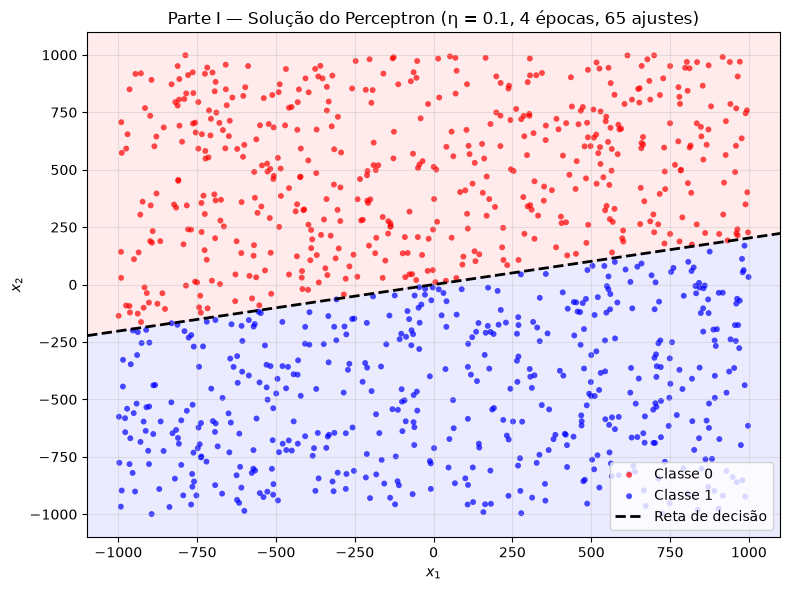

In [11]:
plotar_solucao(X_p1, yd_p1, resultado_p1.w_final, theta=THETA,
               titulo=f'Parte I — Solução do Perceptron '
                      f'(η = {ETA_PARTE1}, {resultado_p1.epocas} épocas, '
                      f'{resultado_p1.total_ajustes} ajustes)')
plt.tight_layout()
plt.show()

## 3. Parte II — Experimentação

Com identificador **0**, a equipe usa o arquivo `data020262.txt`. O algoritmo é o mesmo da Parte I (degrau com $\vartheta = 0$, treino até a convergência), repetido **10 vezes** para cada uma das 6 configurações

$$\eta \times I = \{0{,}4;\ 0{,}1;\ 0{,}01\} \times \{(-100, +100),\ (-0{,}5, +0{,}5)\}.$$

### Normalização dos atributos

No arquivo `data020262.txt`, os atributos $x_1$ e $x_2$ variam aproximadamente de $-1000$ a $+1000$, enquanto a entrada de viés vale $-1$. Sem normalização, algumas execuções ultrapassaram **200 mil épocas** até a convergência, o que tornava inviável rodar as 60 execuções do experimento.

O motivo é a diferença de escala. A cada correção, $w_1$ e $w_2$ mudam em $\eta \cdot x_i$, que chega a centenas de unidades, enquanto $w_0$ muda apenas $\eta$. A inclinação da reta se ajusta rápido, mas sua posição (o limiar) se ajusta muito devagar. Com cada atributo levado para $[-1, 1]$ por `normalizar_atributos` (Seção 1.1), todas as entradas ficam na mesma ordem de grandeza do viés e a convergência passou a ser muito mais rápida.

A normalização é uma transformação linear de cada eixo, então o problema continua linearmente separável e o algoritmo continua sendo o mesmo da Parte I. Os gráficos desta parte estão no espaço normalizado.

In [12]:
ARQUIVO_PARTE2 = 'data020262.txt'
ETAS_PARTE2 = [0.4, 0.1, 0.01]
INTERVALOS_PARTE2 = [(-100, 100), (-0.5, 0.5)]
# repetições (10), limiar (0) e treino até convergir já são os padrões das funções

X_p2, yd_p2 = carregar_dados(ARQUIVO_PARTE2)
# normaliza cada atributo para [-1, 1] (justificativa no texto acima)
X_p2, _ = normalizar_atributos(X_p2)
print(f"Atributos normalizados: x1 em [{X_p2[:, 0].min():.2f}, {X_p2[:, 0].max():.2f}], "
      f"x2 em [{X_p2[:, 1].min():.2f}, {X_p2[:, 1].max():.2f}].")

(1000, 1, 3)
[data020262.txt] 1000 exemplos carregados (classe 0: 566, classe 1: 434).
Atributos normalizados: x1 em [-1.00, 1.00], x2 em [-1.00, 1.00].


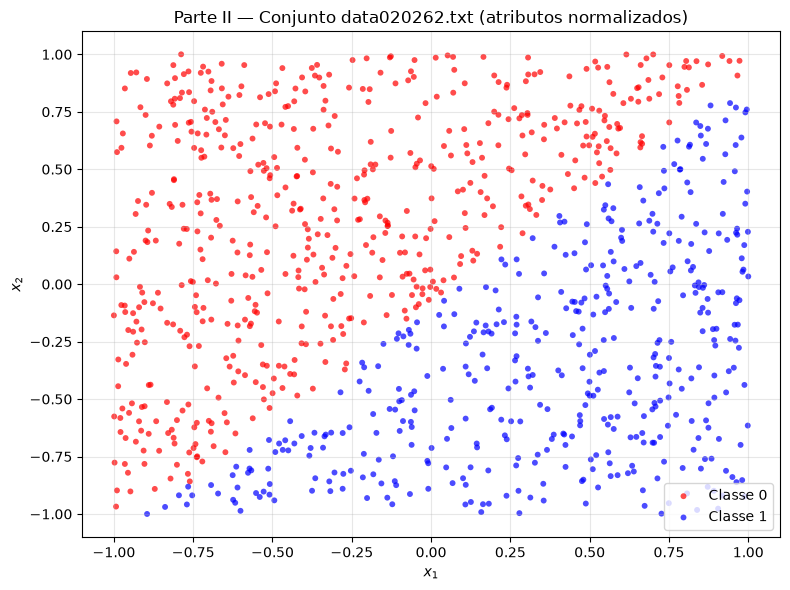

In [13]:
# Visão geral do conjunto
plotar_dados(X_p2, yd_p2, titulo=f'Parte II — Conjunto {ARQUIVO_PARTE2} (atributos normalizados)')
plt.tight_layout()
plt.show()

In [14]:
# célula para apenas executar as rotinas de treino
semente_p2 = random.randrange(2**32)
print(f"Semente sorteada para esta execução: {semente_p2}")

df_result_p2 = executar_experimentos(X_p2, yd_p2, ETAS_PARTE2, INTERVALOS_PARTE2, rng=semente_p2, verbose=False)

Semente sorteada para esta execução: 1101864395


In [15]:
# célula para exibir apenas a tabela resumida dos resultados do experimento
tabela_result_p2 = tabela_experimentos(df_result_p2)
tabela_result_p2

Taxa de Aprendizado,Intervalo de Pesos,Qtde Ajustes,Min Épocas,Max Épocas
η = 0.4,"(-100, +100)",565.90 ± 358.48,9,393
η = 0.4,"(-0.5, +0.5)",783.90 ± 537.36,6,172
η = 0.1,"(-100, +100)",1355.10 ± 343.40,10,111
η = 0.1,"(-0.5, +0.5)",920.80 ± 598.05,7,183
η = 0.01,"(-100, +100)",12864.20 ± 6799.70,23,781
η = 0.01,"(-0.5, +0.5)",631.10 ± 342.17,9,335


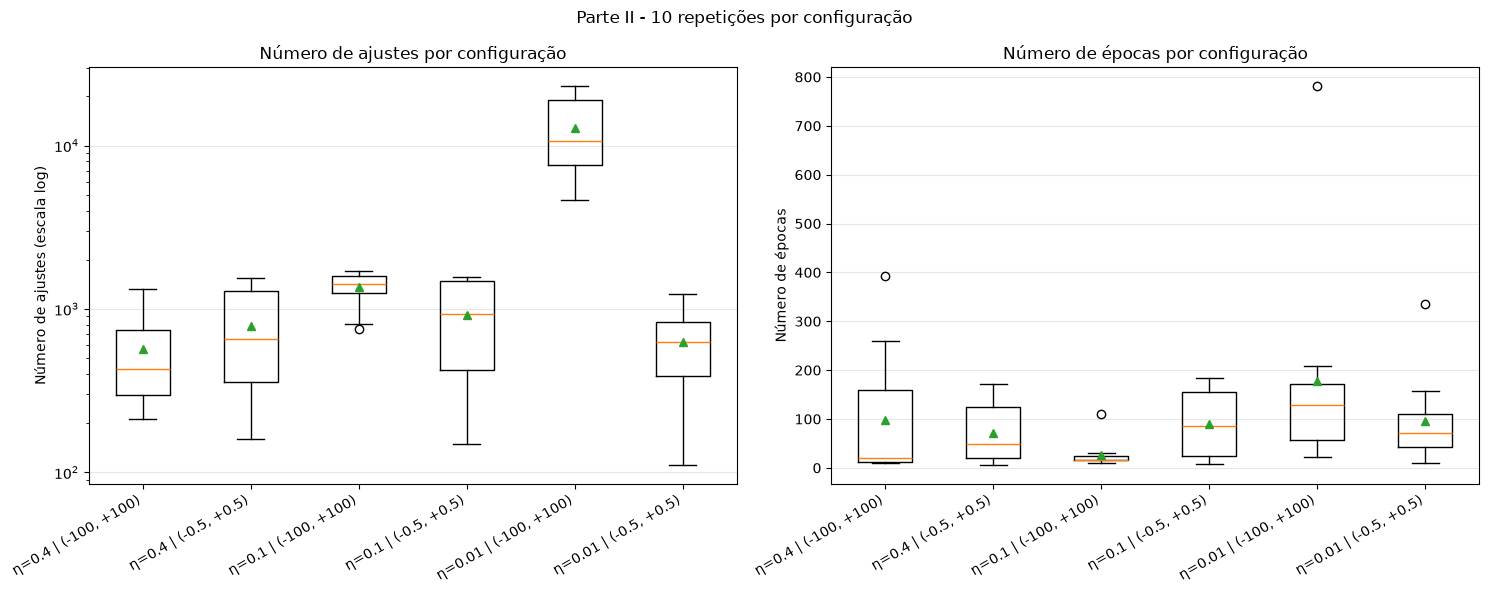

In [16]:
# número de repetições lido do próprio resultado, em vez de uma constante separada
plotar_boxplots(df_result_p2,
                titulo=f'Parte II - {df_result_p2["repeticao"].max()} repetições por configuração')
plt.tight_layout()
plt.show()

### Discussão dos resultados

Olhando a tabela e os boxplots, a configuração com η = 0,01 e pesos iniciais em (−100, +100) é claramente a que mais demora. Sua média de ajustes fica na casa dos milhares, bem acima de todas as outras, e no boxplot de ajustes (em escala log) a caixa dela fica sozinha, acima das demais. A segunda maior média costuma ser a de η = 0,1 com (−100, +100), e as outras quatro configurações ficam na mesma faixa. Como a semente muda a cada execução, os valores exatos também mudam, mas esse padrão se repetiu em todas as vezes que rodamos o experimento.

À primeira vista, parece que a taxa de aprendizado e o intervalo dos pesos têm efeitos separados, mas na verdade eles estão ligados. Como usamos θ = 0, o neurônio só olha o sinal de $u = \mathbf{w} \cdot \mathbf{x}$ para decidir a classe. Se todos os pesos forem multiplicados por um mesmo número positivo, o sinal de $u$ não muda, então a reta de decisão continua a mesma. Por causa disso, treinar com uma taxa η começando de pesos sorteados em um intervalo I dá exatamente os mesmos erros e os mesmos ajustes que treinar com η = 1 começando de pesos sorteados em I/η. Basta dividir a regra $\mathbf{w} \leftarrow \mathbf{w} + \eta\,e\,\mathbf{x}$ por η para ver isso.

Assim, cada uma das seis configurações pode ser vista como um treino com η = 1 que começa com pesos de tamanhos diferentes:

| Configuração | Equivale a começar com pesos em |
|---|---|
| η = 0,4 e (−0,5, +0,5) | ±1,25 |
| η = 0,1 e (−0,5, +0,5) | ±5 |
| η = 0,01 e (−0,5, +0,5) | ±50 |
| η = 0,4 e (−100, +100) | ±250 |
| η = 0,1 e (−100, +100) | ±1000 |
| η = 0,01 e (−100, +100) | ±10000 |

Com os dados normalizados, cada correção muda os pesos em um valor por volta de 1. Se os pesos começam muito grandes, a reta inicial é praticamente aleatória e o neurônio precisa de muitas correções só para desfazer esse começo antes de chegar a uma reta que separe as classes. É o que acontece com η = 0,01 e (−100, +100), que equivale a começar com pesos de até 10000, e, em menor grau, com η = 0,1 e (−100, +100), que equivale a 1000. Quando os pesos começam pequenos (as outras quatro configurações), esse ponto de partida é rapidamente "esquecido" depois das primeiras correções, e quem define o resultado passam a ser os próprios dados. Por isso essas quatro ficaram na mesma faixa.

Também chama atenção a variação dentro de uma mesma configuração. Em todas as repetições os dados, a ordem dos exemplos e a taxa de aprendizado são os mesmos, só muda o sorteio dos pesos iniciais. Mesmo assim, algumas repetições convergiram em poucas épocas e outras levaram centenas. Isso acontece porque uma pequena mudança no começo altera qual exemplo é errado primeiro, o que muda todas as correções seguintes. O número de épocas varia ainda mais que o de ajustes, porque um ou dois exemplos perto da fronteira podem obrigar o treino a rodar várias épocas extras com pouquíssimos erros, o que explica os pontos isolados no boxplot de épocas.

Para dizer se uma configuração é melhor ou pior que outra, comparamos as caixas dos boxplots. Se as caixas não se encostam, a diferença é maior que a variação causada pelo sorteio e pode ser considerada real. Se elas se sobrepõem, a diferença pode ser só sorte. Como o experimento não usa semente fixa, também levamos em conta se a diferença se repete quando o experimento é rodado de novo. Com esses critérios, dá para afirmar que η = 0,01 com (−100, +100) é a pior configuração já que sua caixa fica separada das demais em todas as execuções. A configuração η = 0,1 com (−100, +100) aparece em uma posição intermediária, com a segunda maior média de ajustes, mas sua caixa às vezes se sobrepõe e às vezes não às de outras configurações, então essa diferença é menos firme. Entre as quatro configurações restantes, as caixas se sobrepõem na maior parte das vezes; em uma execução ou outra, duas delas podem aparecer separadas, mas essa separação não se repete nas execuções seguintes, então não representa uma diferença consistente. Por isso, essas quatro devem ser consideradas equivalentes. Com apenas 10 repetições e tanta variação, não é possível apontar qual delas é a melhor, para isso seriam necessárias mais repetições e um teste estatístico.

A principal conclusão do experimento é que a taxa de aprendizado sozinha não diz muito. O que importa é a relação entre o tamanho dos pesos iniciais e o tamanho do passo de correção. Uma taxa pequena só atrapalha de verdade quando é combinada com pesos iniciais grandes.

## 4. Parte III - Validação *Holdout* em Problema Não-Linearmente Separável

Arquivo `dataHoldout20262.txt`, dividido aleatoriamente em 70% para treino e 30% para teste, com semente igual ao identificador da equipe (0). 

Configuração do neurônio:

| Item | Valor | 
|---|---|
| Ativação | degrau, $\vartheta = 0$ | 
| $\eta$ | 0,1 | 
| Pesos iniciais | $U(-0{,}5, +0{,}5)$ | 
| Épocas | 100, com os exemplos em ordem aleatória a cada época | 
| Atributos | normalizados para $[-1, 1]$, com limites calculados só no treino |

**Taxa de aprendizado:** No algoritmo de convergência do Perceptron, Haykin (2009, cap. 1) define $\eta$ como uma constante positiva no intervalo $0 < \eta \le 1$. Adotamos $\eta = 0{,}1$, um valor pequeno dentro desse intervalo e o mesmo usado na Parte I.

**Normalização:** Neste conjunto, $x_1$ varia de 0 a cerca de 360, enquanto $x_2$ varia de $-1$ a $+1$. Com escalas tão diferentes, as correções eram dominadas por $x_1$: na versão sem normalização, o treino fez 29.618 ajustes em 100 épocas, ou seja, cerca de 42% dos exemplos eram corrigidos a cada época e a reta oscilava sem se estabilizar. Por isso, cada atributo é normalizado para $[-1, 1]$ com `normalizar_atributos`. Os limites vêm só do conjunto de treino, para que o teste continue representando dados nunca vistos.

Como o problema não é linearmente separável, nenhuma época termina sem erros: o treino sempre roda as 100 épocas e o vetor final é a "solução possível".

> HAYKIN, S. *Neural Networks and Learning Machines*. 3. ed. Upper Saddle River: Pearson, 2009.

In [17]:
ARQUIVO_PARTE3 = 'dataHoldout20262.txt'
ETA_PARTE3 = 0.1
INTERVALO_PARTE3 = (-0.5, 0.5)
EPOCAS_PARTE3 = 100
FRAC_TREINO = 0.7
THETA = 0.0

X_p3, yd_p3 = carregar_dados(ARQUIVO_PARTE3)

(1000, 3)
[dataHoldout20262.txt] 1000 exemplos carregados (classe 0: 492, classe 1: 508).


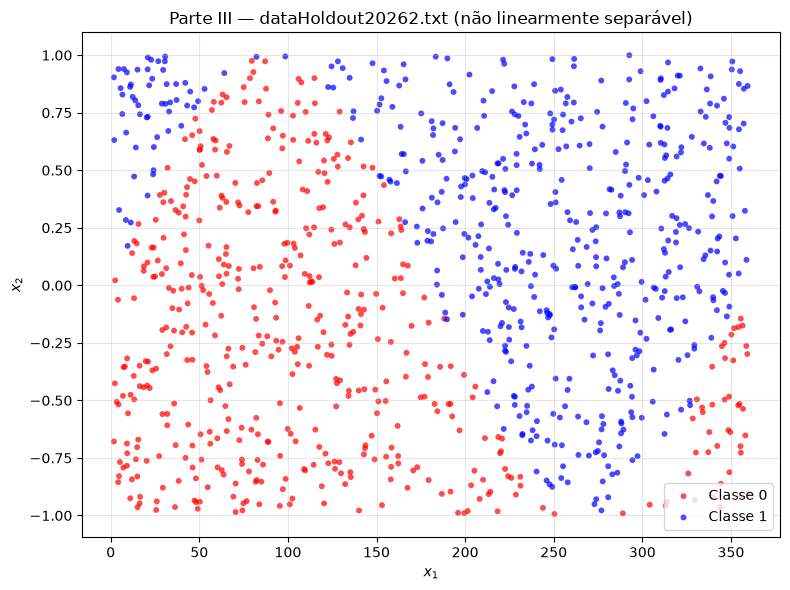

In [18]:
# gráfico inicial: as classes se misturam, logo nenhuma reta as separa sem erros
plotar_dados(X_p3, yd_p3, titulo='Parte III — dataHoldout20262.txt (não linearmente separável)')
plt.tight_layout()
plt.show()

In [19]:
# Divisão holdout 70/30 com a semente da equipe
X_treino, X_teste, yd_treino, yd_teste = dividir_holdout(
    X_p3, yd_p3, frac_treino=FRAC_TREINO, semente=identificador)

# Normalização por atributo: limites calculados só no treino e reaplicados no teste
# (exemplos de teste podem ficar levemente fora de [-1, 1], o que é esperado)
X_treino, limites_p3 = normalizar_atributos(X_treino)
X_teste, _ = normalizar_atributos(X_teste, limites_p3)

print("Formato treino:", X_treino.shape)
print("Formato teste: ", X_teste.shape)
print(f"Limites do treino: mínimos {limites_p3[0]}, máximos {limites_p3[1]}")

Formato treino: (700, 2)
Formato teste:  (300, 2)
Limites do treino: mínimos [ 1.77839314 -0.99356347], máximos [359.78894128   0.994249  ]


In [20]:
# Treinamento por 100 épocas, embaralhando os exemplos a cada época (semente da equipe)
resultado_p3 = treinar_perceptron(X_treino, yd_treino, eta=ETA_PARTE3,
                                  intervalo=INTERVALO_PARTE3, theta=THETA,
                                  max_epocas=EPOCAS_PARTE3, embaralhar=True,
                                  rng=identificador)
imprimir_resumo(resultado_p3)

------------------------------------------------------------
Treinamento NÃO convergiu (limite de épocas).
Número total de ajustes no vetor de pesos: 16669
Número de épocas executadas: 100
Vetor inicial de pesos: [ 0.13696169 -0.23021329 -0.45902648]
Vetor final de pesos:   [0.03696169 0.14337468 0.32263386]
------------------------------------------------------------


In [21]:
# Previsão do neurônio para todos os exemplos de teste e de treino (vetorizada, sem listas)
y_teste = prever(X_teste, resultado_p3.w_final, THETA)
y_treino = prever(X_treino, resultado_p3.w_final, THETA)

print("Primeiras 10 previsões (teste):", y_teste[:10])
print("Primeiros 10 rótulos reais:    ", yd_teste[:10])

Primeiras 10 previsões (teste): [0 1 1 0 1 0 1 1 0 1]
Primeiros 10 rótulos reais:     [1 1 1 0 1 1 1 1 0 0]


### 4.1 Matriz de confusão (conjunto de teste)

Matriz de Confusão (linhas = real, colunas = previsto):
[[113  31]
 [ 41 115]]


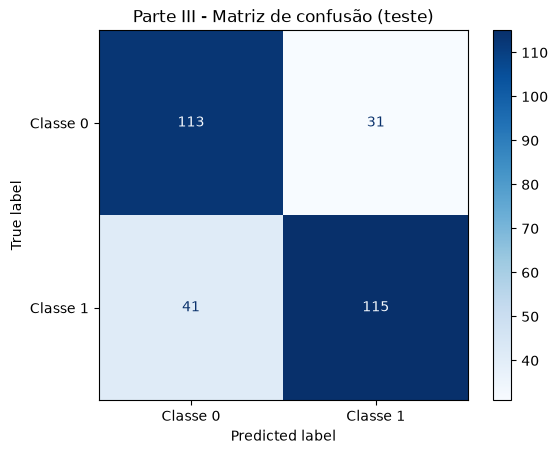

In [22]:
matriz_confusao = confusion_matrix(yd_teste, y_teste, labels=[0, 1])

print("Matriz de Confusão (linhas = real, colunas = previsto):")
print(matriz_confusao)

ConfusionMatrixDisplay(matriz_confusao, display_labels=['Classe 0', 'Classe 1']).plot(cmap='Blues')
plt.title('Parte III - Matriz de confusão (teste)')
plt.show()

### 4.2 e 4.3 Acurácia, precisão, revocação e *F-Score*

In [23]:
# Métricas nos dois conjuntos, com a classe 1 como positiva
metricas = {
    'Treino (70%)': avaliar_classificador(yd_treino, y_treino),
    'Teste (30%)': avaliar_classificador(yd_teste, y_teste),
}

tabela_metricas = PrettyTable()
tabela_metricas.title = 'Parte III — Métricas de desempenho (classe positiva = 1)'
tabela_metricas.field_names = ['Métrica'] + list(metricas)
for nome in metricas['Teste (30%)']:
    tabela_metricas.add_row([nome] + [f"{m[nome]:.2%}" for m in metricas.values()])
tabela_metricas.align['Métrica'] = 'l'

tabela_metricas

Métrica,Treino (70%),Teste (30%)
Acurácia,76.57%,76.00%
Precisão,79.56%,78.77%
Revocação,71.88%,73.72%
F-Score,75.52%,76.16%


A matriz de confusão do conjunto de teste está na Seção 4.1: dos 144 exemplos da classe 0, 113 foram classificados corretamente e 31 foram classificados como classe 1; dos 156 exemplos da classe 1, 115 foram classificados corretamente e 41 foram classificados como classe 0.

A acurácia da solução no conjunto de treinamento é de **76,57%** (no conjunto de teste, 76,00%).

No conjunto de treinamento, a precisão é de **79,56%**, a revocação é de **71,88%** e o F-Score é de **75,52%**. No conjunto de teste, os valores são 78,77%, 73,72% e 76,16%, respectivamente.

### 4.4 Qualidade da solução perante o conjunto de teste

In [24]:
# Números de apoio à discussão, tirados da matriz de confusão e das métricas acima
vn, fp, fn, vp = matriz_confusao.ravel()  # ordem do sklearn para rótulos [0, 1]
# referência: acurácia de quem sempre responde a classe mais frequente no teste
referencia = max(np.mean(yd_teste == 0), np.mean(yd_teste == 1))
diferenca = (metricas['Treino (70%)']['Acurácia'] - metricas['Teste (30%)']['Acurácia']) * 100

print(f"Acertos no teste: {vp + vn} de {len(yd_teste)}")
print(f"Erros no teste:   {fp + fn} ({fp} falsos positivos, {fn} falsos negativos)")
print(f"Acurácia de referência (sempre a classe majoritária): {referencia:.2%}")
print(f"Diferença de acurácia treino - teste: {diferenca:.2f} pontos percentuais")

Acertos no teste: 228 de 300
Erros no teste:   72 (31 falsos positivos, 41 falsos negativos)
Acurácia de referência (sempre a classe majoritária): 52.00%
Diferença de acurácia treino - teste: 0.57 pontos percentuais


No conjunto de teste, o Perceptron acertou 228 dos 300 exemplos, uma acurácia de 76,00%. Para ter uma ideia do que esse número significa, um classificador que respondesse sempre a classe mais comum do teste acertaria 52% dos exemplos. O neurônio fica bem acima disso, então a reta aprendida realmente capturou parte da separação entre as classes, mesmo sem conseguir separá-las por completo.

A acurácia no treino foi de 76,57%, praticamente igual à do teste (diferença de 0,57 ponto percentual). Isso mostra que o neurônio se comporta da mesma forma em exemplos que não viu durante o treinamento, ou seja, não houve sobreajuste. Isso já era esperado, já que o Perceptron tem só três pesos e não tem como "decorar" os 700 exemplos de treino. Os erros que ele comete vêm da limitação do próprio modelo, e não de ter aprendido demais os dados de treino.

Pela matriz de confusão, foram 31 falsos positivos (exemplos vermelhos classificados como azuis) e 41 falsos negativos (exemplos azuis classificados como vermelhos). Como há mais falsos negativos, a revocação (73,72%) ficou um pouco abaixo da precisão (78,77%). Em outras palavras, quando o neurônio diz que um exemplo é da classe 1, ele costuma estar certo, mas ele deixa passar uma parte dos exemplos que realmente são da classe 1. O F-Score de 76,16% resume esse equilíbrio e fica próximo da acurácia, o que é coerente com o conjunto ter quase a mesma quantidade de exemplos de cada classe.

Olhando os gráficos, dá para ver de onde vêm esses erros. A fronteira real entre as classes é ondulada, e a reta aprendida, que desce da esquerda para a direita, só consegue acompanhar o trecho central dessa fronteira. Os falsos positivos são exemplos vermelhos que ficam acima da reta, principalmente na parte de cima, à esquerda do centro. Os falsos negativos vêm em grande parte do grupo de exemplos azuis na parte de baixo, do centro para a direita, que fica inteiro abaixo da reta. Já os grupos dos cantos, azul no canto superior esquerdo e vermelho no canto inferior direito, ficam do lado certo da reta e são classificados corretamente.

Também vale lembrar que, como o problema não é linearmente separável, o treinamento nunca chega a uma época sem erros. Os pesos ficam oscilando até a última época, e o vetor final é apenas a posição em que eles estavam ao fim da centésima época, não necessariamente a melhor reta encontrada durante o treino.

De forma geral, a solução é razoável para o que um único Perceptron consegue fazer, mas existe um limite que não depende de ajustar a taxa de aprendizado ou o número de épocas já que nenhuma reta separa essas classes sem erro. Para melhorar de forma significativa, seria necessário um modelo capaz de formar uma fronteira de decisão curva, como uma rede com mais de uma camada de neurônios.

### 4.5 Solução nos conjuntos de treino e de teste

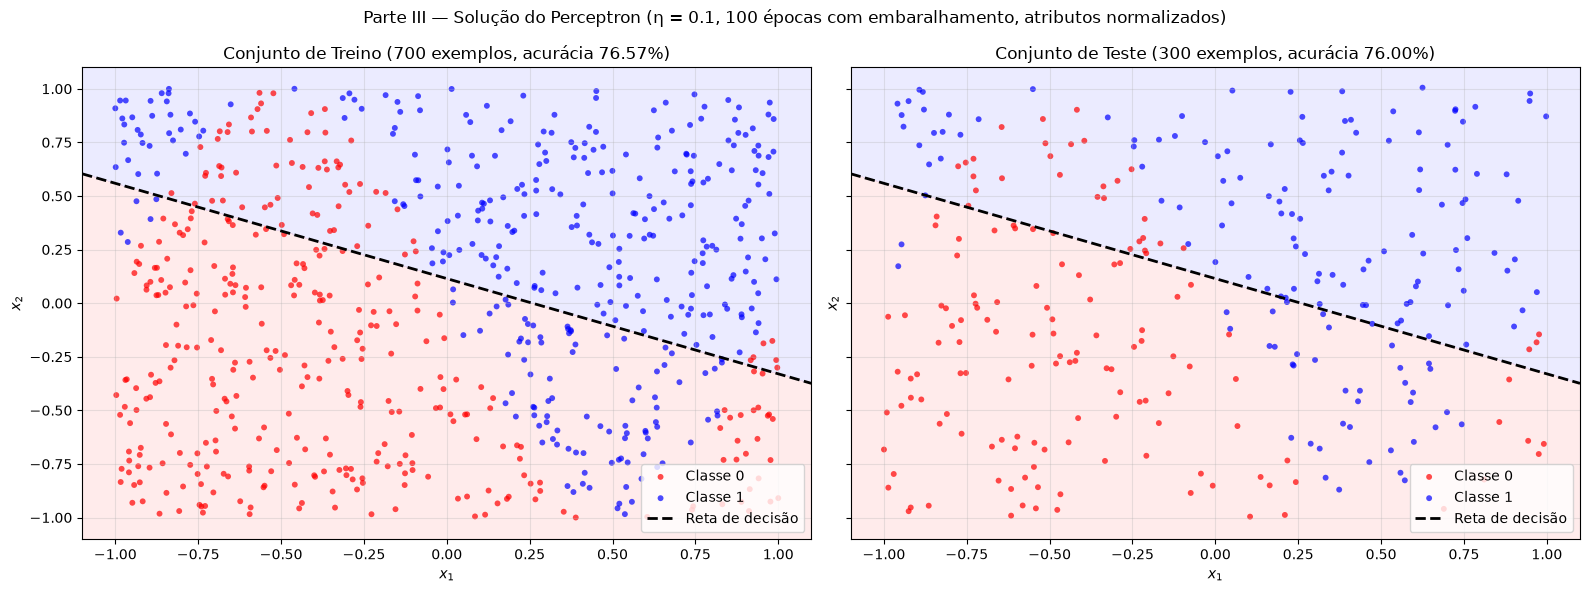

In [25]:
plotar_treino_teste(X_treino, yd_treino, X_teste, yd_teste, resultado_p3.w_final,
                    theta=THETA,
                    titulo=f'Parte III — Solução do Perceptron '
                           f'(η = {ETA_PARTE3}, {EPOCAS_PARTE3} épocas com embaralhamento, '
                           f'atributos normalizados)')
plt.show()